#**Analisis de regresion lineal sobre la felicidad.**

### Jorge Emilio Tello Rivera
### Lenguaje utilizado: Python

## Introducción
Las emociones son dificiles de medir y definir puesto que no se tiene una métrica tangible sobre la cual basarse para determinar que tan triste, asustado, o en este caso en particular, felices son las personas. Sin embargo, en el 2012 el WHR (World Happiness Report) propuso una metodología para estimar el nivel de felicidad promedio de los países.


### Objetivo General
En este reporte se busca analizar, por medio de distintas variables recopiladas entre el 2020 y el 2022, la correlación entre la felicidad y las condiciones sociales y economicas de los países reportados en 2022.

### Objetivos específicos
1.   Analizar la relación entre la felicidad y el GDP de los países.
2.   Identificar variables sociales y económicas relacionadas con el nivel de felicidad.
3. Comparar el desempeño de los modelos de regresión lineal simple y múltiple.





## Metodologia

### Exploración y contextualización de los datos.
La base de datos contiene información de 141 países, donde se registra el nivel de felicidad reportado para 2022 y el GDP correspondiente a 2020. Las variables disponibles se resumen en la siguiente tabla:
#### **Tabla 1. Tipo de datos**

| Variable    | Tipo        | Escala / unidad         | Descripción                                                        |
| ----------- | ----------- | ----------------------- | ------------------------------------------------------------------ |
| `Pais`      | Cualitativo | País                    | Identifica el país analizado.                                      |
| `Felicidad` | Cuantitativo| Escala de 0 a 10        | Representa el nivel promedio de felicidad reportado por cada país. |
| `GDP`       | Cuantitativo| Dólares estadounidenses | Representa el PIB de cada país en 2020.                            |

Los países incluidos presentan condiciones económicas muy diferentes. Se observa que el nivel de felicidad presenta valores entre 2.4038 y 7.8210 en una escala del 1 al 10, mientras que el GDP presenta una variación mucho mayor, desde aproximadamente 1.22 × 10⁹ hasta 2.09 × 10¹³ dólares. Apreciamos una diferencia de escalas significante, ya que el GDP abarca varios órdenes de magnitud entre países, por lo que una relación lineal en su escala original podría no representar adecuadamente el comportamiento de los datos, pues esta no serviría del todo para apreciar bien la relación.

Por otra parte, podría esperarse una relación positiva entre el GDP y la felicidad, debido a que, con una mayor capacidad económica se esperaría tener  mejores condiciones de vida. Sin embargo, esta relación no necesariamente será directamente proporcional, ya que el GDP representa únicamente una dimensión económica y no considera otros factores que pueden influir en la felicidad de la población general.

Analizar la felicidad utilizando únicamente el GDP es bastante limitante para realizar un estudio completo, pues una sola variable económica difícilmente puede explicar un fenómeno influenciado por múltiples condiciones sociales, económicas y de salud. Sin embargo, este solo es un análisis especulativo, por lo que no se puede confirmar sin realizar un modelo concreto.


### Modelo de regresión lineal simple
Con el objetivo de corroborar si se puede determinar la felicidad de un país unicamente con el GDP,  se selecciona como variable para nuestro modelo, de este modo se podrá determinar la relación entre el ingreso económico nacional y el bienestar reportado. Se evaluaron dos especificaciones del modelo, una en escala nominal del GDP ($10^9$ a $10^{13}$) y otra aplicando una transformación logarítmica ($\ln(\text{GDP})$) para poder apreciar de mejor manera el comportamiento de las variables sin la "distorsión" provocada  por las economías de gran escala.

Para evaluar esta relación, se plantean dos especificaciones del modelo de regresión lineal simple:

Modelo 1:$$\text{Felicidad} = \beta_0 + \beta_1 \cdot \text{GDP}  $$
Donde $Y$ representa el nivel de felicidad reportado y $X = \text{GDP}$ corresponde al producto interno bruto en dólares.  

Modelo 2 (Escala Logarítmica):$$\text{Felicidad} = \beta_0 + \beta_1 \cdot \ln(\text{GDP}) $$
Donde $X = \ln(\text{GDP})$ aplica el logaritmo natural para mitigar la disparidad de escalas entre los países analizados.



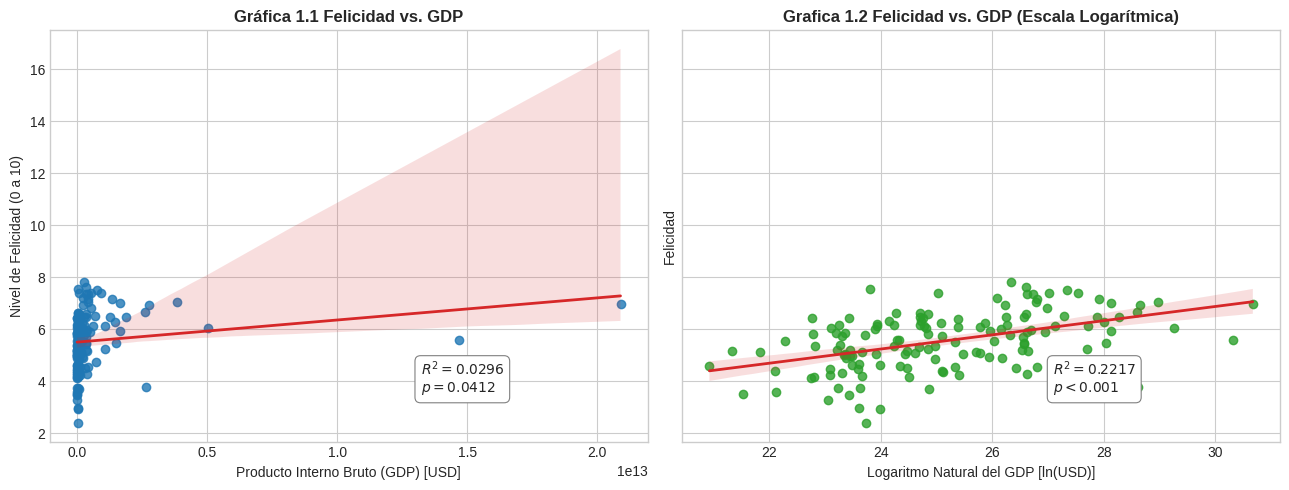

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('A1.2 Felicidad y GDP.csv')
data['log_GDP'] = np.log(data['GDP'])

y = data['Felicidad']
X1 = sm.add_constant(data['GDP'])
X2 = sm.add_constant(data['log_GDP'])

model1 = sm.OLS(y, X1).fit()
model2 = sm.OLS(y, X2).fit()

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

sns.regplot(x='GDP', y='Felicidad', data=data, ax=axes[0], color='#1f77b4',
            line_kws={'color': '#d62728', 'linewidth': 2, 'label': 'Ajuste OLS'})
axes[0].set_title('Gráfica 1.1 Felicidad vs. GDP', fontweight='bold')
axes[0].set_xlabel('Producto Interno Bruto (GDP) [USD]')
axes[0].set_ylabel('Nivel de Felicidad (0 a 10)')
axes[0].annotate(f'$R^2 = {model1.rsquared:.4f}$\n$p = {model1.pvalues["GDP"]:.4f}$',
                 xy=(0.62, 0.12), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", lw=0.8))

sns.regplot(x='log_GDP', y='Felicidad', data=data, ax=axes[1], color='#2ca02c',
            line_kws={'color': '#d62728', 'linewidth': 2, 'label': 'Ajuste OLS'})
axes[1].set_title('Grafica 1.2 Felicidad vs. GDP (Escala Logarítmica)', fontweight='bold')
axes[1].set_xlabel('Logaritmo Natural del GDP [ln(USD)]')
axes[1].annotate(f'$R^2 = {model2.rsquared:.4f}$\n$p < 0.001$',
                 xy=(0.62, 0.12), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", lw=0.8))

plt.tight_layout()
plt.show()

En la escala original (Gráfico 1.1), la mayoría de los países se agrupan verticalmente cerca del origen en valores de GDP bajos y medianos, mientras que muy pocas potencias económicas actúan como puntos de alto apalancamiento, resultando en una recta casi horizontal que enmascara la tendencia real. Por el contrario, la transformación logarítmica (Gráfico 1.2) comprueba que la relación no es lineal sobre la escala original, sino que presenta rendimientos decrecientes. Se observa que incrementos absolutos en el GDP generan mayores aumentos en la felicidad cuando el país parte de un nivel económico bajo, estabilizándose a medida que el ingreso nacional se vuelve muy elevado.




In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# Re-defining models from cell fwnaN9_f9f5a to make this cell runnable independently
data = pd.read_csv('A1.2 Felicidad y GDP.csv')
data['log_GDP'] = np.log(data['GDP'])

y = data['Felicidad']
X1 = sm.add_constant(data['GDP'])
X2 = sm.add_constant(data['log_GDP'])

model1 = sm.OLS(y, X1).fit()
model2 = sm.OLS(y, X2).fit()

tabla_resultados = pd.DataFrame({
    'Modelo': ['Modelo 1 (Escala Original)', 'Modelo 2 (Escala Log)'],
    'X': ['GDP (USD)', 'ln(GDP)'],
    'β0': [f"{model1.params['const']:.4f}", f"{model2.params['const']:.4f}"],
    'β1': [f"{model1.params['GDP']:.4e}", f"{model2.params['log_GDP']:.4f}"],
    'Error (β1)': [f"{model1.bse['GDP']:.4e}", f"{model2.bse['log_GDP']:.4f}"],
    'p-value (β1)': [f"{model1.pvalues['GDP']:.4f}", f"{model2.pvalues['log_GDP']:.4e}"],
    'R²': [f"{model1.rsquared:.4f}", f"{model2.rsquared:.4f}"],
    'R² Ajustado': [f"{model1.rsquared_adj:.4f}", f"{model2.rsquared_adj:.4f}"]
})

# Aplicar el título a la tabla mediante Styler
tabla_resultados_styled = tabla_resultados.style.set_caption("Tabla 2. Comparación modelo original y escala logarítmica")

display(tabla_resultados_styled)

,Modelo,X,β0,β1,Error (β1),p-value (β1),R²,R² Ajustado
0,Modelo 1 (Escala Original),GDP (USD),5.5099,8.5088e-14,4.1295e-14,0.0412,0.0296,0.0227
1,Modelo 2 (Escala Log),ln(GDP),-1.3024,0.2728,0.0434,3.8257e-09,0.2217,0.2161


En la tabla observamos que, en el Modelo 2, la pendiente estimada corresponde a $\beta_1 = 0.2728$. Al tratarse de un modelo log ($\text{Felicidad} = \beta_0 + \beta_1 \ln(\text{GDP})$), el coeficiente se nos permite interpretar que, por cada incremento del $1\%$ en el Producto Interno Bruto de un país, el nivel promedio de felicidad aumenta aproximadamente en $0.002728$ puntos en la escala del 0 a 10 correspondiente a la base de datos. Por otra parte, duplicar el GDP de una nación genera un incremento estimado de $0.2728 \times \ln(2) \approx 0.189$ puntos en el índice de felicidad.

Es importante observar que en el modelo 2, la relación es estadísticamente significativa con un  $p-value = 3.83 \times 10^{-9}$, muy por debajo del estándar de $0.05$, lo que permite rechazar la hipótesis nula de que el ingreso no influye en la felicidad nacional. Sin embargo, las al analizar los datos, estos revelan que el GDP por sí solo explica únicamente el $22.17\%$ de la variabilidad del nivel de felicidad ($R^2 = 0.2217$). Esto implica que casi el $78\%$ de la variación en la percepción de bienestar nacional está determinada por factores no considerados en este modelo simple, lo que nos confirma la necesidad de extender el análisis hacia un modelo de regresión lineal múltiple.  

## Extensión del conjunto de datos
Con el propósito de superar las limitaciones del modelo simple y capturar la naturaleza real de la felicidad, el conjunto de datos original fue enriquecido mediante la integración de tres variables sociales, de salud e institucionales obtenidas de fuentes públicas y oficiales (World Happiness Report 2022):

### 1. Healthy Life Expectancy
Representa la esperanza de vida saludable de la población y permite incorporar al análisis una dimensión relacionada con la salud y la calidad de vida.

Es una variable cuantitativa continua, expresada en años de vida saludable.

### 2. Social Support
Representa la percepción de apoyo social y la solidez de las redes interpersonales de la población, factores relevantes para el bienestar poblacional y la capacidad de afrontar problemas.

Es una variable cuantitativa continua, cuyos valores originales se encuentran indexados en una escala de 0 a 1.

### 3. Perception of Corruption
Sirve como métrica de la confianza en las instituciones y la calidad de la gobernanza.
Es una variable cuantitativa continua, cuyos valores originales se encuentran indexados en una escala de 0 a 1.


Las tres variables seleccionadas fueron obtenidas del archivo de datos correspondiente al World Happiness Report 2022. Los valores utilizados en el análisis corresponden a las variables ponderadas y transformadas presentes en dicho conjunto de datos, por lo que algunos pueden superar la escala original de 0 a 1. Estas transformaciones representan la contribución estimada de cada factor al nivel de felicidad y permiten incorporarlos al modelo de regresión manteniendo su relación con la variable dependiente.

Las variables fueron integradas a la base de datos original mediante una unión por el nombre del país. Durante este proceso se identificaron cinco países que no pudieron ser emparejados con la información adicional, por lo que fueron excluidos del conjunto de datos final para trabajar únicamente con observaciones que contaran con información completa para todas las variables utilizadas.


## Modelo de regresión lineal múltiple

Para profundizar en los factores que determinan el bienestar global, extendimos el análisis inicial de regresión lineal simple a un modelo de regresión lineal múltiple. La variable dependiente ($Y$) se mantiene como el Índice de Felicidad, mientras que el conjunto de variables independientes ($X$) se amplió a cuatro dimensiones:

* PIB Total bruto (GDP): Medido en dólares estadounidenses.

* Apoyo Social (Explained by: Social support)

* Esperanza de Vida Saludable (Explained by: Healthy life expectancy)

* Percepción de Corrupción (Explained by: Perceptions of corruption)

El modelo se estimó mediante Mínimos Cuadrados Ordinarios (OLS) sobre la muestra depurada de $N = 141$ países. Adicionalmente, se calcularon los coeficientes estandarizados ($\beta^*$) para evaluar la importancia relativa de cada variable de forma independiente a sus unidades de medida.



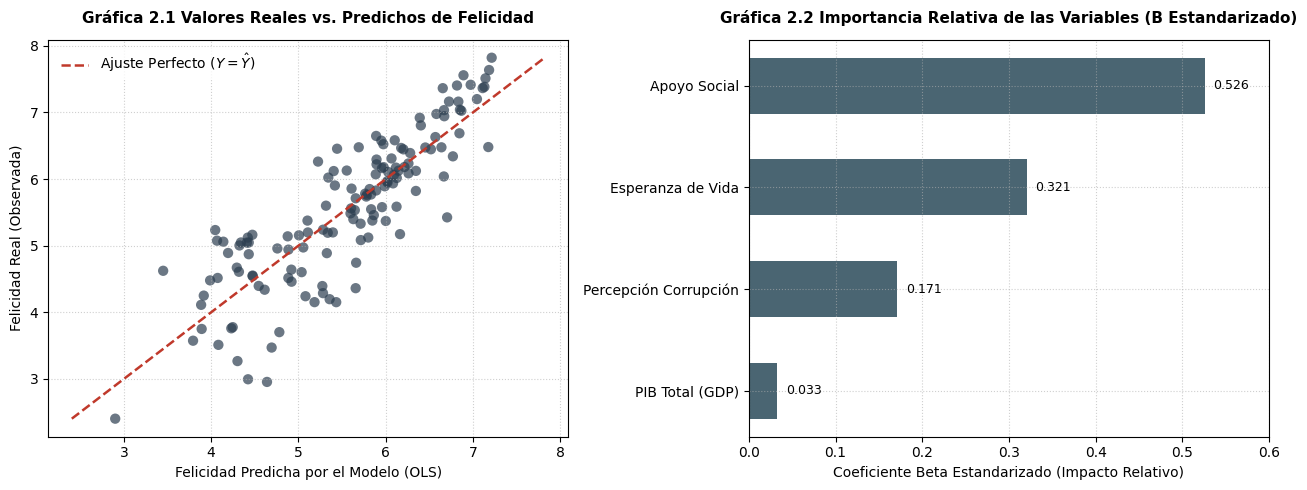

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Cargar y preparar datos
df_orig = pd.read_csv('A1.2 Felicidad y GDP.csv')
df_whr = pd.read_excel('WHR22_Data_Figure_2.1.xls')

df_whr['Country_clean'] = df_whr['Country'].str.replace('*', '', regex=False).str.strip()
df_whr['Country_clean'] = df_whr['Country_clean'].replace({
    'Hong Kong S.A.R. of China': 'Hong Kong',
    'Eswatini, Kingdom of': 'Eswatini'
})

paises_amarillos = ['Venezuela', 'Taiwan Province of China', 'Turkmenistan', 'North Cyprus', 'Palestinian Territories']
df_merged = pd.merge(df_orig, df_whr, left_on='Pais', right_on='Country_clean')
df_final = df_merged[~df_merged['Pais'].isin(paises_amarillos)].copy()

# 2. Definir variables y ajustar OLS
y = df_final['Felicidad']
X = df_final[['GDP', 'Explained by: Social support', 'Explained by: Healthy life expectancy', 'Explained by: Perceptions of corruption']]
X_const = sm.add_constant(X)

model = sm.OLS(y, X_const).fit()

# Betas estandarizados
X_std = (X - X.mean()) / X.std()
y_std = (y - y.mean()) / y.std()
betas = sm.OLS(y_std, sm.add_constant(X_std)).fit().params.drop('const')

# 3. Generar Gráficas Profesionales Sobrias
plt.figure(figsize=(13, 5))

# Estilo corporativo/sobrio
primary_color = '#2c3e50'
accent_color = '#4a6572'
line_color = '#c0392b'

y_pred = model.predict(X_const)

# Subplot 1: Observado vs Predicho
plt.subplot(1, 2, 1)
plt.scatter(y_pred, y, color=primary_color, alpha=0.7, edgecolors='none', s=55)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color=line_color, linestyle='--', linewidth=1.8, label='Ajuste Perfecto ($Y = \\hat{Y}$)')
plt.title('Gráfica 2.1 Valores Reales vs. Predichos de Felicidad', fontsize=11, fontweight='bold', pad=12)
plt.xlabel('Felicidad Predicha por el Modelo (OLS)', fontsize=10)
plt.ylabel('Felicidad Real (Observada)', fontsize=10)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Barras de Importancia Relativa
betas_sorted = betas.sort_values(ascending=True)
names_map = {
    'Explained by: Social support': 'Apoyo Social',
    'Explained by: Healthy life expectancy': 'Esperanza de Vida',
    'Explained by: Perceptions of corruption': 'Percepción Corrupción',
    'GDP': 'PIB Total (GDP)'
}
betas_sorted.index = [names_map[i] for i in betas_sorted.index]

plt.subplot(1, 2, 2)
bars = plt.barh(betas_sorted.index, betas_sorted.values, color=accent_color, height=0.55)
plt.title('Gráfica 2.2 Importancia Relativa de las Variables (B Estandarizado)', fontsize=11, fontweight='bold', pad=12)
plt.xlabel('Coeficiente Beta Estandarizado (Impacto Relativo)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(0, 0.6)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}', ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('regresion_multiple_profesional.png', dpi=300)
plt.show()

Con este modelo podemos obtener dos conclusiones:

* Los valores Reales vs. Predichos muestran una alineación estrecha de los datos alrededor de la línea de ajuste perfecto ($Y = \hat{Y}$),  reduciendo significativamente la dispersión de los errores en comparación con el modelo simple usado originalmente.

* Al comparar los coeficientes Beta estandarizados, se observa que el Apoyo Social ($\beta^ = 0.526$) es, con diferencia, el factor con mayor peso relativo en el modelo, seguido por la Esperanza de Vida ($\beta^ = 0.321$). El PIB Total ($\beta^ = 0.033$) muestra un impacto marginal mínimo en presencia de los demás factores analizados para determinar el nivel de felicidad.

Incorporar las tres variables del WHR junto al PIB representó un salto en la capacidad explicativa del modelo, pasando de un $R^2 = 0.228$ en la regresión simple a un $R^2 = 0.7313$ en la múltiple. La proximidad del $R^2$ ajustado ($0.7234$) ratifica que la ganancia en varianza explicada es genuina y no un sesgo por la adición de variables.


#### Estadistico F
Con la finalidad de corroborar la validez de nuestro modelo, se realizará un estadistico F a modo de determinar si la relación entre las variables de entrada y lo predicho por nuestro modelo es estadisticamente significativo.

Esta prueba contrasta las siguientes hipótesis:

Hipótesis Nula ($H_0$): $\beta_1 = \beta_2 = \beta_3 = \beta_4 = 0$ (Ninguna de las variables independientes explica linealmente la variación en la felicidad).

Hipótesis Alternativa ($H_1$): Al menos uno de los coeficientes $\beta_j \neq 0$ (El modelo conjunto posee capacidad explicativa estadísticamente significativa).

El estadístico $F$ mide la proporción entre la varianza explicada por el modelo ($EMS$) y la varianza no explicada o del error ($RMS$):$$F = \frac{EMS}{RMS} = \frac{\frac{ESS}{m}}{\frac{RSS}{n - m - 1}}$$Donde:

$n = 141$: Tamaños de la muestra total de países analizados.

$m = 4$: Número de variables independientes (PIB Total, Apoyo Social, Esperanza de Vida y Percepción de Corrupción)

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Cargar y preparar datos
df_orig = pd.read_csv('A1.2 Felicidad y GDP.csv')
df_whr = pd.read_excel('WHR22_Data_Figure_2.1.xls')

df_whr['Country_clean'] = df_whr['Country'].str.replace('*', '', regex=False).str.strip()
df_whr['Country_clean'] = df_whr['Country_clean'].replace({
    'Hong Kong S.A.R. of China': 'Hong Kong',
    'Eswatini, Kingdom of': 'Eswatini'
})

paises_amarillos = ['Venezuela', 'Taiwan Province of China', 'Turkmenistan', 'North Cyprus', 'Palestinian Territories']
df_merged = pd.merge(df_orig, df_whr, left_on='Pais', right_on='Country_clean')
df_final = df_merged[~df_merged['Pais'].isin(paises_amarillos)].copy()

# 2. Definir Y (Felicidad) y X (Predictores)
y = df_final['Felicidad'].values
X = df_final[['GDP', 'Explained by: Social support', 'Explained by: Healthy life expectancy', 'Explained by: Perceptions of corruption']].values

# Agregar constante (columna de 1s para la intersección)
X_const = np.column_stack([np.ones(len(X)), X])

# 3. Estimación del modelo por Mínimos Cuadrados Ordinarios (OLS)
beta = np.linalg.inv(X_const.T @ X_const) @ X_const.T @ y
y_pred = X_const @ beta

# 4. Parámetros de grados de libertad
n = len(y)      # Número de observaciones (141)
m = X.shape[1]  # Número de variables independientes (4)

df_modelo = m           # Grados de libertad del modelo (4)
df_error = n - m - 1    # Grados de libertad del error (136)

# 5. Cálculo de Sumas de Cuadrados
y_mean = np.mean(y)
TSS = np.sum((y - y_mean)**2)        # Total Sum of Squares
ESS = np.sum((y_pred - y_mean)**2)   # Explained Sum of Squares
RSS = np.sum((y - y_pred)**2)        # Residual Sum of Squares

# 6. Cálculo de Cuadrados Medios (EMS y RMS)
EMS = ESS / df_modelo               # Explained Mean Square
RMS = RSS / df_error                # Residual Mean Square

# 7. Cálculo del Estadístico F y su p-value
F_stat = EMS / RMS
p_value_F = stats.f.sf(F_stat, df_modelo, df_error)

# 8. Despliegue de resultados
print("=== CALCULO DEL ESTADISTICO F ===")
print(f"Muestra (n): {n}")
print(f"Variables independientes (m): {m}")
print(f"Grados de libertad regresión (df_modelo): {df_modelo}")
print(f"Grados de libertad error (df_error): {df_error}\n")

print(f"ESS (Suma de cuadrados explicada): {ESS:.4f}")
print(f"RSS (Suma de cuadrados residual):  {RSS:.4f}")
print(f"EMS = ESS / m:                    {EMS:.4f}")
print(f"RMS = RSS / (n - m - 1):          {RMS:.4f}\n")

print(f"Estadístico F (EMS / RMS):        {F_stat:.4f}")
print(f"Valor p (p-value):                {p_value_F:.4e}")

=== CALCULO DEL ESTADISTICO F ===
Muestra (n): 141
Variables independientes (m): 4
Grados de libertad regresión (df_modelo): 4
Grados de libertad error (df_error): 136

ESS (Suma de cuadrados explicada): 123.4354
RSS (Suma de cuadrados residual):  45.3526
EMS = ESS / m:                    30.8588
RMS = RSS / (n - m - 1):          0.3335

Estadístico F (EMS / RMS):        92.5372
Valor p (p-value):                7.8521e-38


Al comparar el valor calculado $F = 92.5372$ contra el valor crítico teórico para un nivel de significancia $\alpha = 0.05$ ($F_{\text{crítico}} \approx 2.438$), el valor obtenido supera ampliamente el umbral de rechazo.

Al observar el $p-valor$ ($p = 7.85 \times 10^{-38} < 0.0001$), se observa que la probabilidad de obtener un estadístico de esta magnitud por azar es prácticamente nula. Por lo tanto, se rechaza la hipótesis nula ($H_0$), lo que concluye que las variables explicativas consideradas poseen un efecto conjunto significativo sobre el índice de felicidad global.

El estadístico $F = 92.54$ ($p < 0.001$) demuestra la validez estadística global de la regresión.


### Comparación de modelos y conclusiones
Al comparar ambos modelos obtenemos lo siguiente
#### **Tabla 3. Comparación de ambos modelos**

| Métrica | Regresión Lineal Simple (PIB) | Regresión Lineal Múltiple | Diferencias |
| :--- | :--- | :--- | :--- |
| **Variables Predictoras ($m$)** | $1$ (PIB Total) | $4$ (PIB Total + 3 del WHR) | $+3$ variables explicativas |
| **Variabilidad Explicada ($R^2$)** | $22.80\%$ | **$73.13\%$** | **$+50.33\%$** de varianza capturada |
| **$R^2$ Ajustado ($R_{\text{adj}}^2$)** | $22.24\%$ | **$72.34\%$** | Confirma ganancia real sin sobreajuste |
| **Significancia Global ($F$)** | $40.97$ ($p < 0.001$) | **$92.54$** ($p < 10^{-37}$) | Incremento sustancial en solidez conjunta |
| **Efecto Marginal del PIB ($\beta^*$)** | Significativo ($\beta^* = 0.477$) | No significativo ($\beta^* = 0.033$, $p = 0.467$) | Absorbido por salud y apoyo social |

Se concluye que la adición de las tres variables del World Happiness Report incrementó la varianza explicada en más de 50 puntos porcentuales, demostrando cuantitativamente que la felicidad no es una función lineal del volumen económico bruto de una nación.

El hallazgo más relevante reside en la pérdida de significancia del PIB Total ($\beta^* = 0.033$, $p = 0.467$) al introducir variables de capital humano e institucional. Esto evidencia que el producto interno bruto actúa como un indicador macroeconómico genérico; por sí solo, el volumen total de una economía no se traduce automáticamente en felicidad individual si no está canalizado hacia la construcción de, por ejemplo, redes de Apoyo Social ($\beta^* = 0.526$).

Se observa que la variación del índice de felicidad entre países está impulsada fundamentalmente por factores de cohesión humana e infraestructura de vida: el Apoyo Social (F=74.97) y la Esperanza de Vida (F=25.65) concentran la mayor parte del poder explicativo.

Si se desease continuar el trabajo, se sugiere seguir por la línea del PIB, sin embargo, este debería estar enfocado al PIB per Capita de modo que pueda estar mayormente relacionado con las personas, de este modo podría haber una mayor relación entre la felicidad y el valor del mismo.

##Referencias


* Helliwell, J. F., Layard, R., Sachs, J. D., De Neve, J.-E., Aknin, L. B., & Wang, S. (Eds.). (2022). World Happiness Report 2022. Sustainable Development Solutions Network. https://www.worldhappiness.report/ed/2022/
*  Google. (2026). *Gemini* [Modelo de lenguaje de inteligencia artificial] (Generar codigo de graficas y tablas en python). [https://gemini.google.com/](https://gemini.google.com/)


